In [ ]:
# 19. Develop a CNN model to classify images into ten object categories. 
# Perform image preprocessing, model training and testing, and display the 
# classification accuracy. 
# Use Dataset -  CIFAR-10 

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:
df = pd.read_csv('cifar-10.csv')

print(df.head())
print("Dataset shape:", df.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [3]:
X = df.drop('label', axis=1).values
y = df['label'].values

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [4]:
# X = X.astype('float32') / 255.0

# X = X.reshape(-1, 32, 32, 3)

# print("Image shape:", X.shape)



# Separate features and labels
X = df.drop('label', axis=1).values
y = df['label'].values

# Normalize pixel values
X = X.astype('float32') / 255.0

# Correct RGB channel arrangement
X = X.reshape(-1, 3, 32, 32)
X = X.transpose(0, 2, 3, 1)

print("Image shape:", X.shape)

Image shape: (50000, 32, 32, 3)


In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [6]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

In [7]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(32, 32, 3)),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\prerna\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.4381 - loss: 1.5621 - val_accuracy: 0.5235 - val_loss: 1.3534
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.5692 - loss: 1.2159 - val_accuracy: 0.5882 - val_loss: 1.1774
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.6218 - loss: 1.0728 - val_accuracy: 0.6137 - val_loss: 1.1150
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.6587 - loss: 0.9771 - val_accuracy: 0.6354 - val_loss: 1.0457
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.6881 - loss: 0.8953 - val_accuracy: 0.6479 - val_loss: 1.0167
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7098 - loss: 0.8285 - val_accuracy: 0.6530 - val_loss: 1.0079
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7319 - loss: 0.7629 - val_accuracy: 0.6606 - val_loss: 0.9987
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.7558 - loss: 0.6997 - va

In [10]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)

print("Classification Accuracy:",
      test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6551 - loss: 1.0728
Test Loss: 1.0727643966674805
Classification Accuracy: 65.50999879837036 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


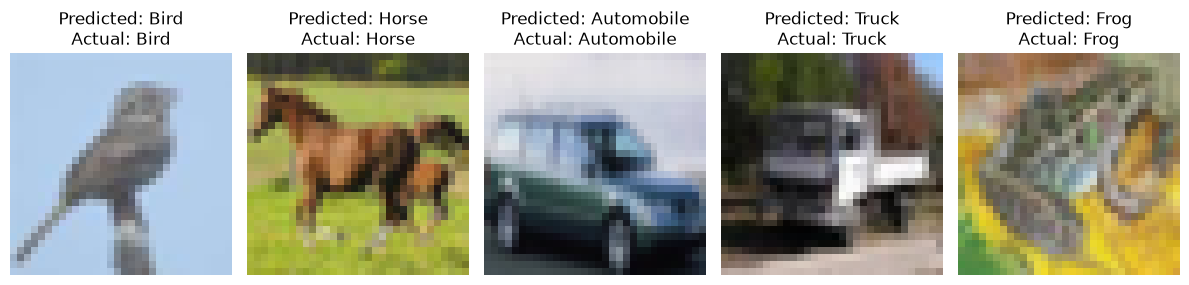

In [11]:
predictions = model.predict(x_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(x_test[i])

    plt.title(
        "Predicted: " + class_names[predicted_labels[i]] +
        "\nActual: " + class_names[y_test[i]]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

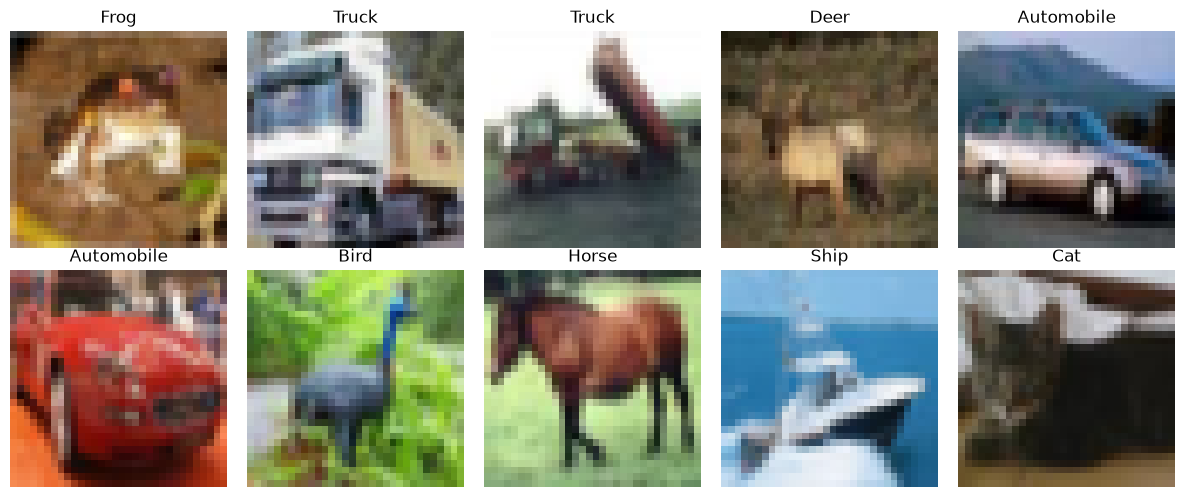

In [12]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X[i], interpolation='nearest')

    plt.title(class_names[y[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()